# Lung: cell–matrix association and recovery of ECM labels from cell context (Figure 4)

Six imaging-mass-cytometry regions of interest (ROIs) of healthy mouse lung from two mice, with 12 annotated
cell types and ten extracellular-matrix (ECM) markers. This notebook redraws every panel of Fig. 4 from the
raw images with Mantpy:

1. **a–c** cell, ECM and joint cell–ECM graphs of one ROI;
2. **d** ECM clusters and their marker profiles;
3. **e** which ECM cluster airway epithelial cells (AECs) contact;
4. **f, g** the matrix that AECs contact inside the bronchovascular-wall cluster;
5. **h, i** one held-out ROI after corrupting 10% of its ECM labels and after reconstruction from cell context;
6. **j** detection of the corrupted labels from cell, joint and ECM context, each mouse held out in turn.

Everything is refitted here. Each value is printed beside the paper's; small differences are expected because
the K-means partition is refitted (11,450 signal patches here, 11,435 in the paper).

**Not rerun here:** the parameter search that chose the graph, feature and classifier settings
(Supplementary Table 6; the selected settings are read from `lung_selected.json`), the graph-rule sensitivity
analysis (Supplementary Fig. 3) and the ROI-held-out controls. These are in the command-line version.

**Runtime: about 1 minute on a CPU** (measured 52 s on a desktop CPU, with the data already downloaded);
no GPU is needed. Requires Mantpy 1.2.0 or newer and `squidpy`
(see `lung_requirements.txt`). Keep `lung_selected.json` beside this notebook.

In [1]:
import sys, subprocess, json, time, warnings
from pathlib import Path
from urllib.request import urlretrieve

if "google.colab" in sys.modules:   # Google Colab only: install the packages
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mantpy==1.2.0", "squidpy"], check=True)
if not Path("lung_selected.json").exists():
    urlretrieve("https://raw.githubusercontent.com/moeghaf/mantpy_reproducibility/main/"
                "notebooks/lung_selected.json", "lung_selected.json")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import mantpy as mt

warnings.filterwarnings("ignore")
T0 = time.perf_counter()
SEED = 0
PATCH_SIZE = 10          # pixels (1 pixel = 1 µm)
GRAPH_ROI = "roi_001"    # ROI drawn in panels a-c and g
EXAMPLE_ROI = "roi_004"  # held-out ROI drawn in panels h and i (mouse 2)
WALL = 1                 # ECM 1, bronchovascular wall
N_REALISATIONS = 5
SETTINGS = json.loads(Path("lung_selected.json").read_text())["mouse"]   # Supplementary Table 6
print("Mantpy", mt.__version__)

Mantpy 1.1.1


## 1. Load the six ROIs

In [2]:
bundle = mt.datasets.balbc_pbs_lung()
cells = bundle.cohort_cells                       # one AnnData of typed cells per ROI
ROIS = list(cells)
mouse = bundle.metadata.set_index("sample_id")["Mouse"].astype(str)
MOUSE_MARK = dict(zip(sorted(mouse.unique()), ["o", "^"]))
CELL_TYPES = sorted(set().union(*[set(a.obs["cell_type"].astype(str)) for a in cells.values()]))
ECM = bundle.ecm_palette
print(f"{len(ROIS)} ROIs, {mouse.nunique()} mice, {len(CELL_TYPES)} cell types, {len(bundle.ecm_names)} ECM markers")
bundle.metadata[["sample_id", "Mouse", "strain", "treatment"]]

6 ROIs, 2 mice, 12 cell types, 10 ECM markers


,sample_id,Mouse,strain,treatment
0,roi_001,mouse_01,BALB/c,PBS
1,roi_002,mouse_01,BALB/c,PBS
2,roi_003,mouse_01,BALB/c,PBS
3,roi_004,mouse_02,BALB/c,PBS
4,roi_005,mouse_02,BALB/c,PBS
5,roi_006,mouse_02,BALB/c,PBS


## 2. ECM patches and clusters (panel d)

Each marker is standardised over the pooled pixels of all ROIs and averaged in 10 × 10-pixel patches.
K-means with three to seven components is scored by the silhouette of the signal patches; the dimmest
component is removed as background and the signal clusters are numbered from the largest.

In [3]:
ecm = mt.pp.ecm_patches_from_images(
    bundle.images, bundle.panel, normalize="pooled_zscore", patch_size=PATCH_SIZE,
    features=["mean"], ecm_K=None, background_quantile=1e-9,   # drops only the single dimmest patch per ROI
)
selection = mt.pp.select_ecm_cluster_count(ecm, signal_k_range=range(2, 7), random_state=SEED)
partition = mt.pp.cluster_ecm_patches(
    ecm, n_clusters=selection.selected_total_k, method="kmeans", subset="all", random_state=SEED, n_init=10,
)
mt.pp.remove_background_patches(ecm, partition, background="lowest_mean", order_signal_by="size")
mt.pp.attach_ecm_patches(cells, ecm)
tables = {roi: cells[roi].uns["ecm_patches"] for roi in ROIS}
LABELS = {roi: tables[roi]["ecm_cluster"].to_numpy(int) for roi in ROIS}      # -1 = background
XY = {roi: tables[roi][["x", "y"]].to_numpy(float) for roi in ROIS}
n_total = sum(len(t) for t in tables.values())
n_signal = sum(int((l >= 0).sum()) for l in LABELS.values())
print(f"K-means components selected: {selection.selected_total_k}   (paper: 4)")
print(f"Patches: {n_total:,}   (paper: 27,318)")
print(f"Signal patches in three clusters: {n_signal:,}   (paper: 11,435)")

K-means components selected: 4   (paper: 4)
Patches: 27,318   (paper: 27,318)
Signal patches in three clusters: 11,450   (paper: 11,435)


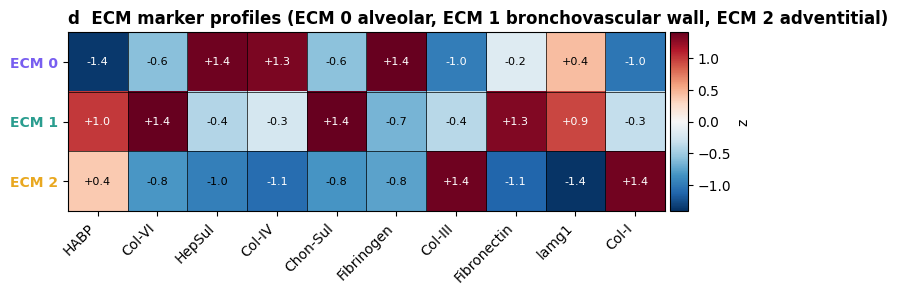

In [4]:
_ = mt.pl.ecm_centroid_heatmap(
    ecm, ecm_names=bundle.ecm_names, K_ecm=3, cluster_colors=ECM,
    title="d  ECM marker profiles (ECM 0 alveolar, ECM 1 bronchovascular wall, ECM 2 adventitial)", figsize=(8, 3.2),
)

## 3. Cell, ECM and joint graphs (panels a–c)

Cells within 15 pixels are connected (Squidpy); adjacent patches are connected on an eight-connected grid;
each cell is linked to its five nearest patches within 15 pixels.

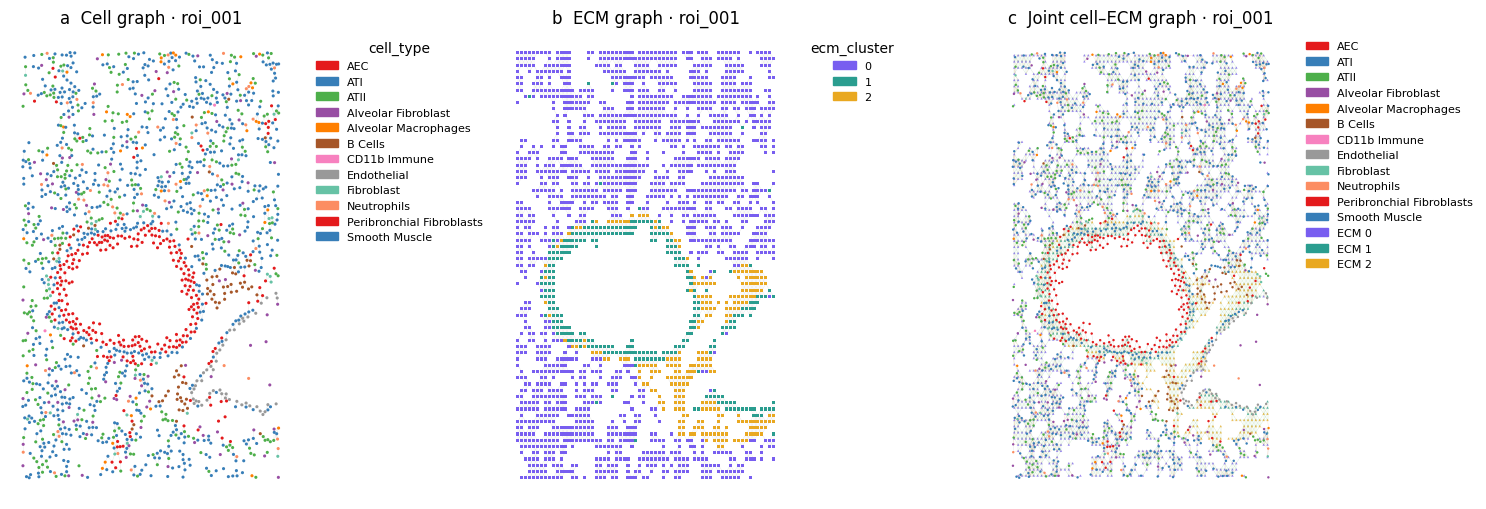

,n_nodes,n_cells,n_ecm,cell_cell_edges,ecm_ecm_edges,cell_ecm_edges
sample,,,,,,
roi_001,6373,1820,4553,3029,17805,9046
roi_002,6456,1903,4553,3308,17805,9450
roi_003,6515,1962,4553,3248,17805,9739
roi_004,6495,1942,4553,3861,17805,9639
roi_005,6377,1824,4553,3261,17805,9043
roi_006,6350,1797,4553,2812,17805,8914


In [5]:
graphs = mt.gr.build_cell_ecm_graphs(
    cells, cell_graph="squidpy", cell_radius=(0, 15),
    ecm_edge_method="grid", ecm_grid_connectivity=8,
    cell_ecm_edge_method="knn", cell_ecm_k=5, cell_ecm_Dmax=15, knn_backend="scipy",
)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
style = dict(node_edgecolor=None, node_linewidth=0, ax_off=True, show=False)
mt.pl.cell_graph(cells[GRAPH_ROI], node_size=5, edge_alpha=0.3, edge_width=0.3, ax=axes[0], **style)
mt.pl.ecm_graph(cells[GRAPH_ROI], node_size=5, node_marker="s", edge_alpha=0.3, edge_width=0.3,
                palette=ECM, ax=axes[1], **style)
mt.pl.cell_ecm_graph(cells[GRAPH_ROI], node_size_cell=3, node_size_ecm=3, edge_alpha=0.2, edge_width=0.3,
                     ecm_palette=ECM, ax=axes[2], **style)
for ax, title in zip(axes, ["a  Cell graph", "b  ECM graph", "c  Joint cell–ECM graph"]):
    ax.set_title(f"{title} · {GRAPH_ROI}")
plt.tight_layout(); plt.show()
pd.DataFrame([vars(row) for row in graphs.summaries]).set_index("sample")

## 4. Which ECM cluster do airway epithelial cells contact? (panel e)

AEC–ECM edges are counted in each ROI and compared with the count expected from the share of all cell–ECM
edges that land on each cluster. Observed and expected counts are summed over the ROIs.

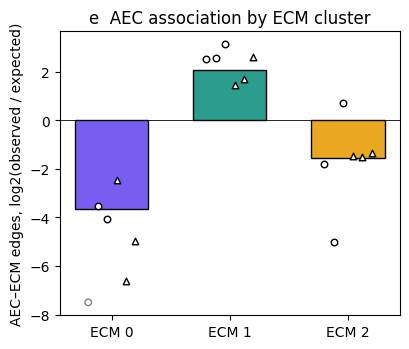

ROIs with a positive ratio, of those with an observed edge: {0: 0, 1: 6, 2: 1} (paper: ECM 1 six of six)


,n_obs,n_exp,log2_enr,paper
cluster,,,,
0,151,1908.78,-3.66,-3.66
1,2505,603.56,2.05,2.05
2,75,218.66,-1.54,-1.54


In [6]:
pooled = mt.tl.cell_ecm_enrichment(cells, "AEC", K_ecm=3, n_perm=0, random_state=SEED)
per_roi = cells[ROIS[0]].uns["cell_ecm_enrichment_per_roi"]
PAPER_E = {0: -3.66, 1: 2.05, 2: -1.54}

fig, ax = plt.subplots(figsize=(4.2, 3.6))
for k in range(3):
    ax.bar(k, pooled.set_index("cluster").loc[k, "log2_enr"], color=ECM[k], edgecolor="black", width=0.62)
    rows = per_roi[per_roi["cluster"].eq(k)].set_index("roi")
    for i, roi in enumerate(ROIS):
        value, seen = rows.loc[roi, "log2_enr"], rows.loc[roi, "n_obs"] > 0   # grey: ROI with no observed edge
        ax.scatter(k + np.linspace(-0.2, 0.2, len(ROIS))[i], value if seen else -7.5,
                   marker=MOUSE_MARK[mouse[roi]], s=22, zorder=3,
                   facecolors="white" if seen else "none", edgecolors="black" if seen else "grey")
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(range(3), ["ECM 0", "ECM 1", "ECM 2"])
ax.set_ylabel("AEC–ECM edges, log2(observed / expected)")
ax.set_title("e  AEC association by ECM cluster")
plt.tight_layout(); plt.show()

table_e = pooled.set_index("cluster")[["n_obs", "n_exp", "log2_enr"]].round(2)
table_e["paper"] = pd.Series(PAPER_E)
signs = per_roi[per_roi["n_obs"] > 0].assign(positive=lambda d: d["log2_enr"] > 0).groupby("cluster")["positive"].sum()
print("ROIs with a positive ratio, of those with an observed edge:", signs.to_dict(), "(paper: ECM 1 six of six)")
table_e

## 5. The matrix that AECs contact within ECM 1 (panels f and g)

Within the bronchovascular-wall cluster, the mean marker profile of patches without an AEC edge is
subtracted from that of patches with one, in each ROI; the six ROIs are averaged with equal weight.

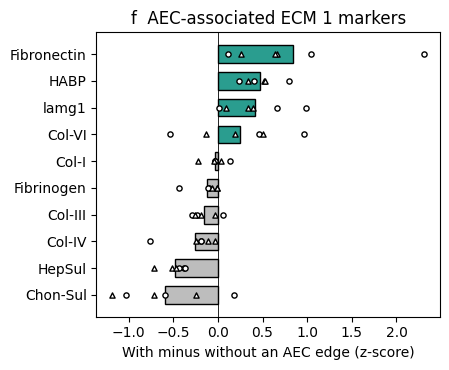

Largest increases (paper: fibronectin +0.84, hyaluronan +0.47, laminin-γ1 +0.42):
Fibronectin    0.84
HABP           0.47
lamg1          0.42
Same sign in all six ROIs: ['HABP', 'HepSul', 'Col-IV', 'Fibrinogen', 'Fibronectin', 'lamg1']


In [7]:
feature_columns = [c for c in tables[ROIS[0]] if c.startswith("feat_")]
contrast, contacted = {}, {}
for roi in ROIS:
    layers = mt.gr.graph_layers(cells[roi])                    # cells x patches matrix of the stored graph
    result = mt.tl.contact_marker_contrast(
        layers.cell_ecm, tables[roi][feature_columns],
        cell_labels=cells[roi].obs["cell_type"].astype(str).to_numpy(), cell_type="AEC",
        patch_labels=LABELS[roi], cluster=WALL, weighting="unique_patch", accumulation_dtype="input",
    )
    contrast[roi] = result.contrast.to_numpy()
    contacted[roi] = result.contact_mask.to_numpy() & (LABELS[roi] == WALL)
contrast = pd.DataFrame.from_dict(contrast, orient="index", columns=bundle.ecm_names)
mean_contrast = contrast.mean().sort_values()

fig, ax = plt.subplots(figsize=(4.6, 3.8))
for i, marker in enumerate(mean_contrast.index):
    ax.barh(i, mean_contrast[marker], color=ECM[WALL] if mean_contrast[marker] > 0 else "#bdbdbd",
            edgecolor="black", height=0.66)
    for roi in ROIS:
        ax.scatter(contrast.loc[roi, marker], i, marker=MOUSE_MARK[mouse[roi]], s=14,
                   facecolors="white", edgecolors="black", zorder=3)
ax.axvline(0, color="black", lw=0.6)
ax.set_yticks(range(len(mean_contrast)), mean_contrast.index)
ax.set_xlabel("With minus without an AEC edge (z-score)")
ax.set_title("f  AEC-associated ECM 1 markers")
plt.tight_layout(); plt.show()

top = mean_contrast.sort_values(ascending=False)
print("Largest increases (paper: fibronectin +0.84, hyaluronan +0.47, laminin-γ1 +0.42):")
print(top.head(3).round(2).to_string())
print("Same sign in all six ROIs:", [m for m in contrast if (np.sign(contrast[m]) == np.sign(contrast[m].iloc[0])).all()])

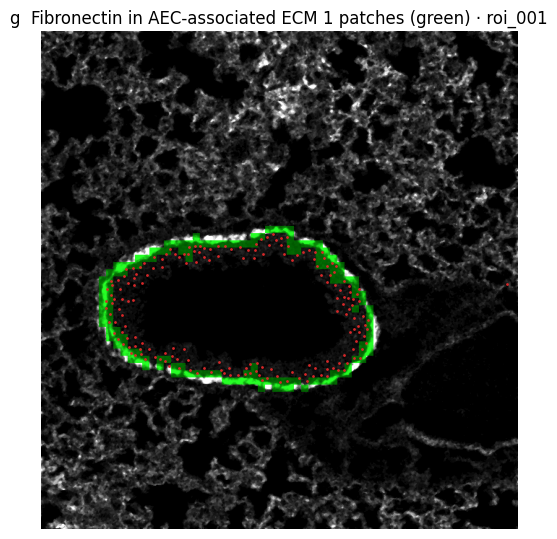

AEC-associated ECM 1 patches in roi_001: 142   (paper: 142)


In [8]:
panel = bundle.panel.loc[bundle.panel["keep"].eq(1)].reset_index(drop=True)
fibronectin = np.asarray(bundle.images[GRAPH_ROI][int(panel.index[panel["name"].eq("Fibronectin")][0])], dtype=float)
image = ndimage.median_filter(fibronectin, size=3, mode="nearest")          # display only
scaled = np.clip(image / np.percentile(image[image > 0], 99), 0, 1)
inside = np.zeros(image.shape, dtype=bool)
for x, y in XY[GRAPH_ROI][contacted[GRAPH_ROI]]:
    inside[int(y - PATCH_SIZE / 2):int(y + PATCH_SIZE / 2), int(x - PATCH_SIZE / 2):int(x + PATCH_SIZE / 2)] = True
rgb = np.repeat(scaled[:, :, None], 3, axis=2)
rgb[inside] = np.stack([0.15 * scaled[inside], 0.35 + 0.65 * scaled[inside], 0.15 * scaled[inside]], axis=1)
aec = cells[GRAPH_ROI].obs["cell_type"].astype(str).eq("AEC").to_numpy()
aec_xy = np.asarray(cells[GRAPH_ROI].obsm["spatial"])[aec]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(rgb)
ax.scatter(aec_xy[:, 0], aec_xy[:, 1], s=4, c="#d62728", linewidths=0)
ax.set_title(f"g  Fibronectin in AEC-associated ECM 1 patches (green) · {GRAPH_ROI}"); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"AEC-associated ECM 1 patches in {GRAPH_ROI}: {int(contacted[GRAPH_ROI].sum())}   (paper: 142)")

## 6. Recover corrupted ECM labels from cell context (panels h–j)

In each ROI, 10% of the signal-patch labels are replaced, half inside square blocks of side 50, 100 or 150
pixels and half as isolated patches, in five seeded realisations (`mt.tl.corrupt_labels`).

A multinomial logistic regression predicts each patch's cluster from the labels of its graph neighbours
(`mt.tl.context_features`): its connected cells (**cell** context), its neighbouring patches (**ECM** context)
or both (**joint**), never from the patch's own label. Each mouse is held out in turn; the model is fitted
on the three uncorrupted ROIs of the other mouse with the settings selected within that mouse
(Supplementary Table 6). A patch is relabelled when its anomaly score exceeds the selected threshold
(`mt.tl.reconstruct_labels`).

In [9]:
corruptions = {
    (roi, r): mt.tl.corrupt_labels(
        LABELS[roi], XY[roi], fraction=0.10, block_fraction=0.5, block_sides=(50, 100, 150),
        min_block_units=20, categories=range(3), random_state=r * 1000 + i,
    )
    for i, roi in enumerate(ROIS) for r in range(N_REALISATIONS)
}
example = corruptions[(EXAMPLE_ROI, 0)]
print(f"{EXAMPLE_ROI}, realisation 0: {int(example.is_corrupted.sum())} of {int((LABELS[EXAMPLE_ROI] >= 0).sum())} "
      f"signal labels replaced; {len(example.blocks)} block(s)   (paper: 150 of 1,503; 1 block)")
example.blocks

roi_004, realisation 0: 151 of 1506 signal labels replaced; 1 block(s)   (paper: 150 of 1,503; 1 block)


,centre_x,centre_y,side,new_label,n_replaced
0,155.521576,100.19117,150.0,2,75


The two functions below translate one row of Supplementary Table 6 into Mantpy calls: the first builds the
selected graph, the second returns the context features of one ROI for a given set of patch labels.

In [10]:
KERNEL = {"none": "uniform", "inv_d": "inverse", "inv_d2": "inverse_square", "gaussian_median": "gaussian"}
NORMALISATION = {"count": "counts", "fraction": "proportions", "log1p_count": "log1p_counts"}


def build_selected_graph(graph):
    """Build the cell-ECM graph of every ROI with one selected rule; returns the cells to read it from."""
    options = dict(cell_graph="mantpy")
    rule = graph["cc_rule"]
    options.update({"knn": dict(cell_edge_method="knn", cell_k=graph["cc_k"], cell_Dmax=graph["cc_radius_px"]),
                    "radius": dict(cell_edge_method="radius", cell_radius=graph["cc_radius_px"]),
                    "delaunay": dict(cell_edge_method="delaunay")}[rule])
    rule, radius = graph["ee_rule"], graph["ee_radius_px"]
    options.update({"grid8": dict(ecm_edge_method="grid", ecm_grid_connectivity=8),
                    "knn": dict(ecm_edge_method="knn", ecm_k=graph["ee_k"], ecm_Dmax=radius),
                    "radius": dict(ecm_edge_method="radius", ecm_r=radius),
                    "delaunay": dict(ecm_edge_method="delaunay", ecm_delaunay_max_length=2 * radius)}[rule])
    rule, reach = graph["ce_rule"], graph["ce_dmax_px"]
    options.update({"knn": dict(cell_ecm_edge_method="knn", cell_ecm_k=graph["ce_k"], cell_ecm_Dmax=reach),
                    "radius": dict(cell_ecm_edge_method="radius", cell_ecm_r=reach or 15.0),
                    "delaunay": dict(cell_ecm_edge_method="delaunay",
                                     cell_ecm_delaunay_max_length=2 * reach if reach else None)}[rule])
    rules = (graph["cc_rule"], graph["ee_rule"], graph["ce_rule"])
    if "knn" in rules:
        options.update(knn_backend="scipy")
    if "delaunay" in rules:
        options.update(delaunay_jitter=1e-6, delaunay_seed=0)
    if graph["ee_include_background_nodes"]:
        target = cells
    else:   # graph over the signal patches only: build it on copies that hold the signal rows
        target = {roi: cells[roi].copy() for roi in ROIS}
        for roi in ROIS:
            target[roi].uns["ecm_patches"] = tables[roi].loc[LABELS[roi] >= 0]
    mt.gr.build_cell_ecm_graphs(target, **options)
    return target


def features(target, roi, setting, labels):
    """Context features of every patch of one ROI, computed from ``labels`` (never the patch's own label)."""
    rows = target[roi].uns["ecm_patches"].index
    keep = tables[roi].index.isin(rows)
    table = mt.tl.context_features(
        target[roi], context=setting["context"], hops=setting["features"]["hops"],
        normalization=NORMALISATION[setting["features"]["composition_norm"]],
        edge_weight=KERNEL[setting["graph"]["edge_weight"]],
        cell_categories=CELL_TYPES, ecm_categories=range(3), ecm_labels=labels[keep],
    )
    return table.reindex(tables[roi].index, fill_value=0.0).to_numpy()

Fit and score every context with each mouse held out. Detection uses the anomaly score
−log P(observed label | context) before any relabelling; the prior-adjusted score divides by the training
label frequency, which removes what label frequency alone explains.

In [11]:
def fit_classifier(X, y, learner):
    scaler = StandardScaler().fit(X) if learner["standardize"] else None
    penalty = learner["penalty"]
    if penalty == "none":
        model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=2000, random_state=SEED)
    elif penalty == "l2":
        model = LogisticRegression(penalty="l2", C=learner["C"], solver="lbfgs", max_iter=2000, random_state=SEED)
    else:   # "l1" or "elasticnet"
        model = LogisticRegression(penalty="elasticnet", C=learner["C"], solver="saga", max_iter=200, tol=1e-3,
                                   l1_ratio=1.0 if penalty == "l1" else learner["l1_ratio"], random_state=SEED)
    model.fit(scaler.transform(X) if scaler else X, y)

    def predict(X):
        p = model.predict_proba(scaler.transform(X) if scaler else X)
        return p / p.sum(axis=1, keepdims=True)
    return predict


def fit_temperature(p, y, grid=(0.5, 0.75, 1.0, 1.5, 2.0, 3.0)):
    """Calibration temperature with the lowest training loss (used by the settings that selected it)."""
    def loss(t):
        q = p ** (1 / t)
        return -np.mean(np.log(np.maximum((q / q.sum(1, keepdims=True))[np.arange(len(y)), y], 1e-12)))
    return min(grid, key=loss)


rows, class_rows, example_maps = [], [], {}
t_fit = time.perf_counter()
for held_out in sorted(mouse.unique()):
    train = [roi for roi in ROIS if mouse[roi] != held_out]
    test = [roi for roi in ROIS if mouse[roi] == held_out]
    y_train = np.concatenate([LABELS[roi][LABELS[roi] >= 0] for roi in train])
    counts = np.bincount(y_train, minlength=3)
    prior = counts / counts.sum()                                     # training label frequencies

    # Label-prior baseline: the same probabilities for every patch.
    for roi in test:
        for r in range(N_REALISATIONS):
            c = corruptions[(roi, r)]
            flat = np.tile((counts + 1e-9) / (counts + 1e-9).sum(), (len(c.labels), 1))
            raw = mt.tl.label_anomaly_scores(c.labels, flat, categories=range(3))
            score = mt.tl.score_label_reconstruction(LABELS[roi], c.labels, c.labels, scores=raw).metrics
            rows.append(dict(context="prior", held_out=held_out, roi=roi, realisation=r, roc_auc=score["roc_auc"]))

    for context in ("cell", "joint", "ecm"):
        setting = SETTINGS[held_out][context]["config"]
        clean = setting["cleaning"]
        target = build_selected_graph(setting["graph"])
        X_train = np.vstack([features(target, roi, setting, LABELS[roi])[LABELS[roi] >= 0] for roi in train])
        predict = fit_classifier(X_train, y_train, setting["learner"])
        temperature = fit_temperature(predict(X_train), y_train) if setting["calibration"] == "temperature" else 1.0
        for roi in test:
            for r in range(N_REALISATIONS):
                c = corruptions[(roi, r)]
                first = predict(features(target, roi, setting, c.labels))
                raw = mt.tl.label_anomaly_scores(c.labels, first, categories=range(3), temperature=temperature)
                adjusted = mt.tl.label_anomaly_scores(c.labels, first, categories=range(3),
                                                      temperature=temperature, prior=prior)
                current = c.labels.copy()
                for _ in range(clean["passes"]):       # ECM and joint context are recomputed after each pass
                    step = mt.tl.reconstruct_labels(
                        current, predict(features(target, roi, setting, current)), categories=range(3),
                        threshold=clean["threshold"], score=clean["anomaly_stat"],
                        min_confidence=clean["min_pred_conf"], coordinates=XY[roi],
                        spatial_radius=clean["gate_radius_px"],
                        min_neighbours=clean["gate_min_neighbours"] if clean["gate_radius_px"] > 0 else 0,
                        majority_smoothing=clean["majority_smoothing"], temperature=temperature,
                    )
                    current = step.labels
                    if not step.relabelled.any():
                        break
                scored = mt.tl.score_label_reconstruction(
                    LABELS[roi], c.labels, current, corrupted=c.is_corrupted,
                    scores={"raw": raw, "prior_adjusted": adjusted},
                )
                rows.append(dict(context=context, held_out=held_out, roi=roi, realisation=r, **scored.metrics))
                class_rows.append(scored.per_class.assign(context=context, roi=roi).reset_index())
                if context == "cell" and r == 0:
                    example_maps[roi] = current
    print(f"{held_out} held out: fitted on {', '.join(train)}")
results = pd.DataFrame(rows)
results["roc_auc_raw"] = results["roc_auc_raw"].fillna(results.pop("roc_auc"))
classes = pd.concat(class_rows, ignore_index=True)
print(f"Fitting and scoring: {time.perf_counter() - t_fit:.0f} s")

mouse_01 held out: fitted on roi_004, roi_005, roi_006


mouse_02 held out: fitted on roi_001, roi_002, roi_003
Fitting and scoring: 23 s


### One held-out ROI before and after reconstruction (panels h and i)

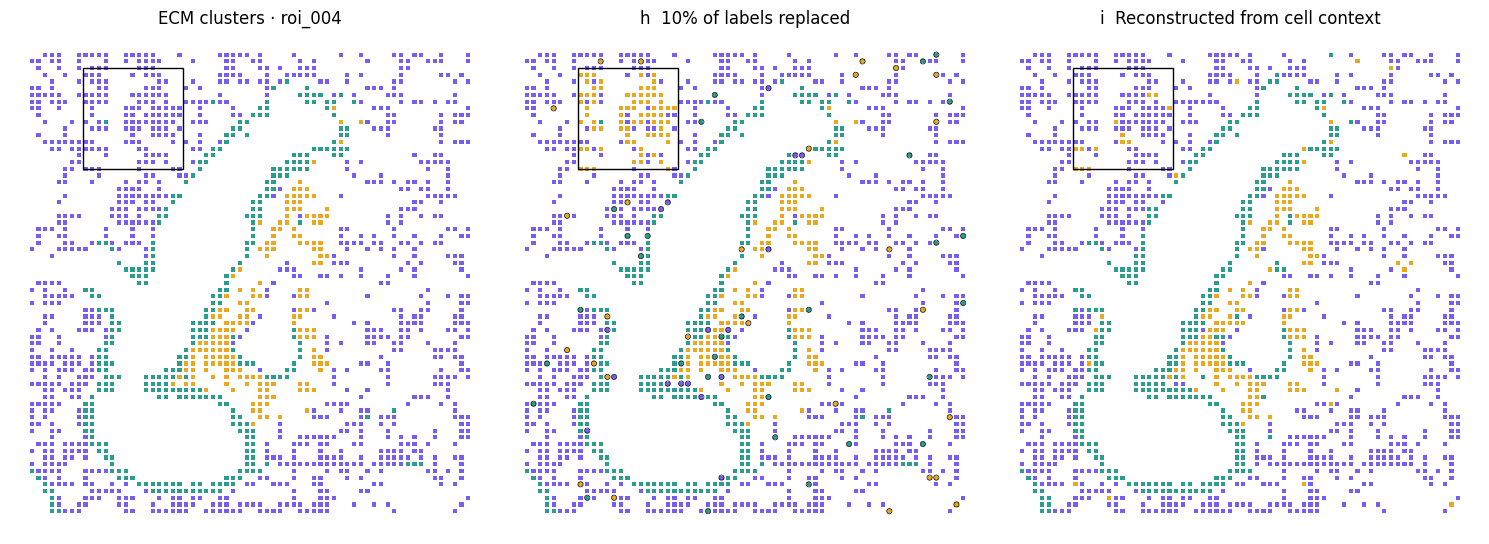

,this run,paper
label accuracy before,0.900,0.900
label accuracy after,0.953,0.951
replaced labels corrected,0.735,0.720


In [12]:
def label_map(ax, labels, title, corruption=None):
    signal = labels >= 0
    ax.scatter(XY[EXAMPLE_ROI][signal, 0], XY[EXAMPLE_ROI][signal, 1], s=9, marker="s", linewidths=0,
               c=[ECM[int(k)] for k in labels[signal]])
    for block in example.blocks.itertuples():
        ax.add_patch(Rectangle((block.centre_x - block.side / 2, block.centre_y - block.side / 2),
                               block.side, block.side, fill=False, edgecolor="black", lw=1))
    if corruption is not None:
        isolated = corruption.is_corrupted & ~corruption.in_block()
        ax.scatter(XY[EXAMPLE_ROI][isolated, 0], XY[EXAMPLE_ROI][isolated, 1], s=14, facecolors="none",
                   edgecolors="black", linewidths=0.5)
    ax.set_title(title); ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
label_map(axes[0], LABELS[EXAMPLE_ROI], f"ECM clusters · {EXAMPLE_ROI}")
label_map(axes[1], example.labels, "h  10% of labels replaced", example)
label_map(axes[2], example_maps[EXAMPLE_ROI], "i  Reconstructed from cell context")
plt.tight_layout(); plt.show()

one = results.query("context == 'cell' and roi == @EXAMPLE_ROI and realisation == 0").iloc[0]
pd.DataFrame({
    "this run": [one.before_accuracy, one.after_accuracy, one.artifact_recovered],
    "paper": [0.900, 0.951, 0.72],
}, index=["label accuracy before", "label accuracy after", "replaced labels corrected"]).round(3)

### Detection of corrupted labels (panel j)

Scores are averaged over the five realisations within each ROI and then over the six ROIs.

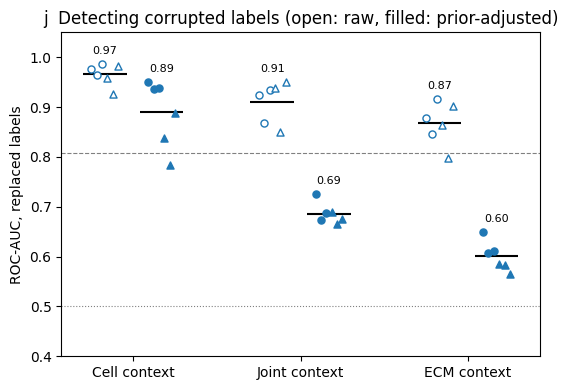

,ROC-AUC,paper,prior-adjusted,paper
cell,0.966,0.97,0.889,0.89
joint,0.911,0.91,0.686,0.70
ecm,0.867,0.87,0.600,0.61
prior,0.808,0.80,NaN,NaN


In [13]:
per_roi_scores = results.groupby(["context", "roi"], sort=False).mean(numeric_only=True).reset_index()
summary = per_roi_scores.groupby("context").mean(numeric_only=True)
ORDER = ["cell", "joint", "ecm"]
NAMES = {"cell": "Cell context", "joint": "Joint context", "ecm": "ECM context"}

fig, ax = plt.subplots(figsize=(5.6, 4))
for i, context in enumerate(ORDER):
    data = per_roi_scores[per_roi_scores["context"].eq(context)].set_index("roi")
    for offset, column, filled in ((-0.17, "roc_auc_raw", False), (0.17, "roc_auc_prior_adjusted", True)):
        for j, roi in enumerate(data.index):
            ax.scatter(i + offset + np.linspace(-0.08, 0.08, len(data))[j], data.loc[roi, column], s=26,
                       marker=MOUSE_MARK[mouse[roi]], facecolors="C0" if filled else "white", edgecolors="C0", zorder=3)
        ax.hlines(data[column].mean(), i + offset - 0.13, i + offset + 0.13, color="black", lw=1.5)
        ax.text(i + offset, data[column].max() + 0.02, f"{data[column].mean():.2f}", ha="center", fontsize=8)
ax.axhline(summary.loc["prior", "roc_auc_raw"], color="grey", ls="--", lw=0.8)
ax.axhline(0.5, color="grey", ls=":", lw=0.8)
ax.set_xticks(range(3), [NAMES[c] for c in ORDER]); ax.set_ylim(0.4, 1.05)
ax.set_ylabel("ROC-AUC, replaced labels"); ax.set_title("j  Detecting corrupted labels (open: raw, filled: prior-adjusted)")
plt.tight_layout(); plt.show()

PAPER_J = {"cell": (0.97, 0.89), "joint": (0.91, 0.70), "ecm": (0.87, 0.61), "prior": (0.80, np.nan)}
table_j = pd.DataFrame({
    "ROC-AUC": summary["roc_auc_raw"], "paper": {k: v[0] for k, v in PAPER_J.items()},
    "prior-adjusted": summary["roc_auc_prior_adjusted"], "paper ": {k: v[1] for k, v in PAPER_J.items()},
}).loc[ORDER + ["prior"]].round(3)
table_j

In [14]:
cell = per_roi_scores[per_roi_scores["context"].eq("cell")]
recovery = classes[classes["context"].eq("cell")].groupby(["roi", "cluster"])[["n_corrupted", "n_restored"]].sum()
recovery = (recovery["n_restored"] / recovery["n_corrupted"]).groupby("cluster").mean()
ranks = per_roi_scores[per_roi_scores["context"].isin(ORDER)].pivot(index="roi", columns="context", values="roc_auc_prior_adjusted")
pd.DataFrame({
    "this run": [cell.roc_auc_raw.mean(), cell.roc_auc_raw.min(), cell.roc_auc_raw.max(),
                 cell.artifact_recovered.mean(), cell.artifact_recovered.min(), cell.artifact_recovered.max(),
                 cell.pristine_relabel_rate.mean(), cell.before_accuracy.mean(), cell.after_accuracy.mean(),
                 recovery[0], recovery[1], recovery[2], (ranks.idxmax(axis=1) == "cell").sum()],
    "paper": [0.97, 0.93, 0.99, 0.70, 0.52, 0.78, 0.021, 0.90, 0.95, 0.80, 0.48, 0.33, 6],
}, index=["cell context ROC-AUC, mean", "  lowest ROI", "  highest ROI",
          "replaced labels corrected, mean", "  lowest ROI", "  highest ROI",
          "uncorrupted labels made wrong", "label accuracy before", "label accuracy after",
          "corrected, ECM 0 (alveolar)", "corrected, ECM 1 (bronchovascular wall)", "corrected, ECM 2 (adventitial)",
          "ROIs where cell context ranks first"]).round(3)

,this run,paper
"cell context ROC-AUC, mean",0.966,0.970
lowest ROI,0.926,0.930
highest ROI,0.987,0.990
"replaced labels corrected, mean",0.694,0.700
lowest ROI,0.508,0.520
highest ROI,0.774,0.780
uncorrupted labels made wrong,0.021,0.021
label accuracy before,0.900,0.900
label accuracy after,0.951,0.950
"corrected, ECM 0 (alveolar)",0.789,0.800


In [15]:
out = Path("results/lung_fig4"); out.mkdir(parents=True, exist_ok=True)
results.to_csv(out / "reconstruction_per_realisation.csv", index=False)
per_roi_scores.to_csv(out / "reconstruction_per_roi.csv", index=False)
table_j.to_csv(out / "fig4j_vs_paper.csv")
table_e.to_csv(out / "fig4e_vs_paper.csv")
contrast.to_csv(out / "fig4f_marker_contrast.csv")
print(f"Total runtime: {time.perf_counter() - T0:.0f} s")

Total runtime: 52 s
